<a href="https://colab.research.google.com/github/ajayvardhanreddykanchani-coder/Traffic_congestion_prediction/blob/main/Traffic_congestion_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install pandas numpy matplotlib scikit-learn joblib streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 26.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 73.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [streamlit]


In [2]:
import pandas as pd
import numpy as np
import sklearn

print("All libraries are ready!")
print("Pandas version:", pd.__version__)

All libraries are ready!
Pandas version: 2.2.3


In [3]:
import os
import pandas as pd
import urllib.request
import gzip
import io

os.makedirs("data", exist_ok=True)
os.makedirs("output", exist_ok=True)

url = (
    "https://archive.ics.uci.edu/ml/"
    "machine-learning-databases/00492/"
    "Metro_Interstate_Traffic_Volume.csv.gz"
)

with urllib.request.urlopen(url) as response:
    compressed_data = response.read()

with gzip.GzipFile(
    fileobj=io.BytesIO(compressed_data)
) as file:
    df = pd.read_csv(file)

df.to_csv(
    "data/Metro_Interstate_Traffic_Volume.csv",
    index=False
)

print("Module 1 completed!")
print("Dataset shape:", df.shape)
print(df.head())

Module 1 completed!
Dataset shape: (48204, 9)
  holiday    temp  rain_1h  snow_1h  clouds_all weather_main  \
0     NaN  288.28      0.0      0.0          40       Clouds   
1     NaN  289.36      0.0      0.0          75       Clouds   
2     NaN  289.58      0.0      0.0          90       Clouds   
3     NaN  290.13      0.0      0.0          90       Clouds   
4     NaN  291.14      0.0      0.0          75       Clouds   

  weather_description            date_time  traffic_volume  
0    scattered clouds  2012-10-02 09:00:00            5545  
1       broken clouds  2012-10-02 10:00:00            4516  
2     overcast clouds  2012-10-02 11:00:00            4767  
3     overcast clouds  2012-10-02 12:00:00            5026  
4       broken clouds  2012-10-02 13:00:00            4918  


In [4]:
import pandas as pd

df = pd.read_csv(
    "data/Metro_Interstate_Traffic_Volume.csv"
)

df = df.drop_duplicates().copy()
df = df.replace(r"^\s*$", pd.NA, regex=True)

df["date_time"] = pd.to_datetime(
    df["date_time"], errors="coerce"
)

df = df.dropna(subset=["date_time"]).copy()

df["hour"] = df["date_time"].dt.hour
df["day"] = df["date_time"].dt.day
df["month"] = df["date_time"].dt.month
df["year"] = df["date_time"].dt.year
df["day_of_week"] = df["date_time"].dt.dayofweek
df["is_weekend"] = (
    df["day_of_week"] >= 5
).astype(int)

df["is_holiday"] = (
    df["holiday"].notna()
    & (df["holiday"].astype(str).str.lower() != "none")
).astype(int)

df = df.drop(
    columns=["date_time", "holiday", "weather_description"],
    errors="ignore"
)

df["weather_main"] = df["weather_main"].fillna("Unknown")

numeric_columns = df.select_dtypes(
    include="number"
).columns

for column in numeric_columns:
    df[column] = df[column].fillna(df[column].median())

df = pd.get_dummies(
    df, columns=["weather_main"], dtype=int
)

df.to_csv("data/processed_traffic.csv", index=False)

print("Module 2 completed!")
print("Processed dataset shape:", df.shape)
print(df.head())

Module 2 completed!
Processed dataset shape: (48187, 23)
     temp  rain_1h  snow_1h  clouds_all  traffic_volume  hour  day  month  \
0  288.28      0.0      0.0          40            5545     9    2     10   
1  289.36      0.0      0.0          75            4516    10    2     10   
2  289.58      0.0      0.0          90            4767    11    2     10   
3  290.13      0.0      0.0          90            5026    12    2     10   
4  291.14      0.0      0.0          75            4918    13    2     10   

   year  day_of_week  ...  weather_main_Clouds  weather_main_Drizzle  \
0  2012            1  ...                    1                     0   
1  2012            1  ...                    1                     0   
2  2012            1  ...                    1                     0   
3  2012            1  ...                    1                     0   
4  2012            1  ...                    1                     0   

   weather_main_Fog  weather_main_Haze  weather

In [5]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

df = pd.read_csv("data/processed_traffic.csv")

X = df.drop(columns=["traffic_volume"])
y = df["traffic_volume"]

X = X.replace([np.inf, -np.inf], np.nan)
X = X.fillna(X.median())

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

models = {
    "Decision Tree": DecisionTreeRegressor(
        max_depth=20, random_state=42
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=100, max_depth=20,
        random_state=42, n_jobs=-1
    ),
    "KNN": make_pipeline(
        StandardScaler(),
        KNeighborsRegressor(n_neighbors=5)
    )
}

results = []

for name, model in models.items():
    print("Training:", name)
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(
            mean_squared_error(y_test, predictions)
        ),
        "R2 Score": r2_score(y_test, predictions)
    })

print(pd.DataFrame(results).sort_values("RMSE"))
print("Module 3 completed!")

Training: Decision Tree
Training: Random Forest
Training: KNN
           Model         MAE         RMSE  R2 Score
1  Random Forest  197.612907   352.449622  0.968929
0  Decision Tree  241.938580   466.365094  0.945598
2            KNN  740.024652  1043.617975  0.727574
Module 3 completed!


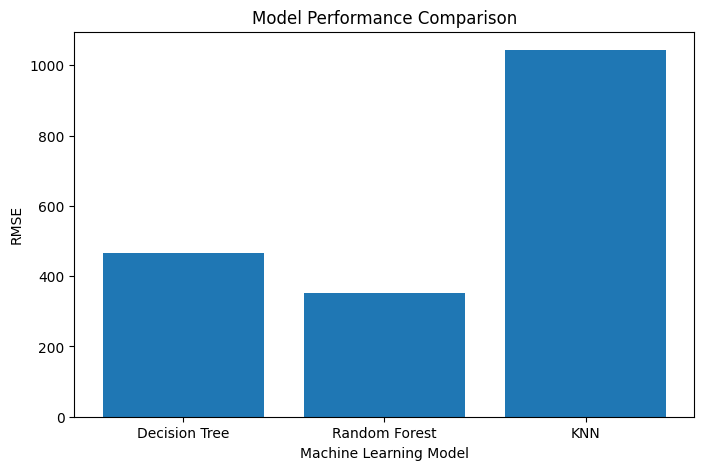

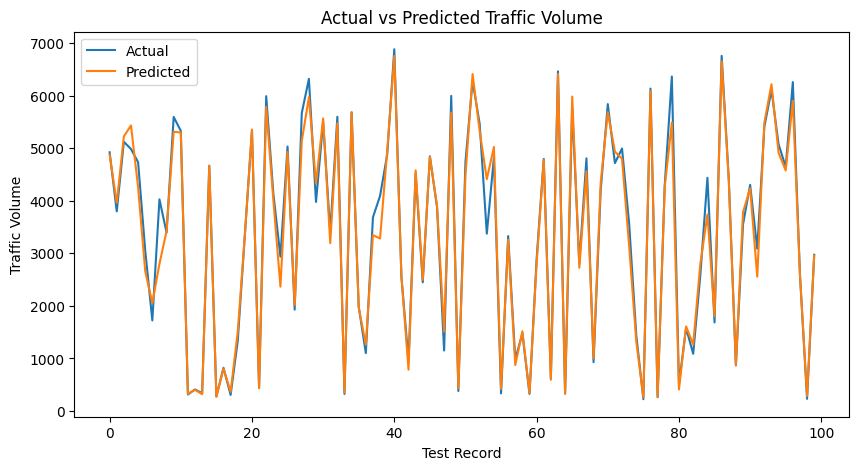

Best model: Random Forest
Module 4 completed!


In [6]:
import matplotlib.pyplot as plt
import os

os.makedirs("output", exist_ok=True)

# Compare model evaluation results
results_df = pd.DataFrame(results)
results_df.to_csv("output/model_evaluation.csv", index=False)

plt.figure(figsize=(8, 5))
plt.bar(results_df["Model"], results_df["RMSE"])
plt.xlabel("Machine Learning Model")
plt.ylabel("RMSE")
plt.title("Model Performance Comparison")
plt.savefig("output/model_comparison.png")
plt.show()

# Actual versus predicted values for the best model
best_name = results_df.sort_values("RMSE").iloc[0]["Model"]
best_model = models[best_name]
predictions = best_model.predict(X_test)

plt.figure(figsize=(10, 5))
plt.plot(y_test.iloc[:100].to_numpy(), label="Actual")
plt.plot(predictions[:100], label="Predicted")
plt.xlabel("Test Record")
plt.ylabel("Traffic Volume")
plt.title("Actual vs Predicted Traffic Volume")
plt.legend()
plt.savefig("output/actual_vs_predicted.png")
plt.show()

print("Best model:", best_name)
print("Module 4 completed!")